# Deep Learning e Classificação Multimodal

Notebook de apresentação técnica do papel do *deep learning* tabular, sua dependência dos sinais de PLN e o funcionamento do classificador multimodal.

Esse notebook utiliza o código de `src/models/` e a configuração `src/config/models.yaml` do próprio repositório.

### Roteiro

1. [Preparação e rastreabilidade](#1-preparação-e-rastreabilidade)
2. [Deep Learning tabular e dependência de PLN](#2-deep-learning-tabular-e-dependência-de-pln)
3. [Composição e funcionamento do multimodal](#3-composição-e-funcionamento-do-multimodal)
4. [Por que uma MLP?](#4-por-que-uma-mlp)
5. [Execução e carregamento da fusão](#5-execução-e-carregamento-da-fusão)
6. [Curvas, métricas e matriz de confusão](#6-curvas-métricas-e-matriz-de-confusão)
7. [Resultados finais e interpretação](#7-resultados-finais-e-interpretação)


## 1. Preparação e rastreabilidade

Configuração de algumas variáveis do notebook:

- `RODADA_FEATURES` e `RODADA_FUSAO` permitem selecionar rodadas específicas, com `None` a seleção se torna automática.
- `EXECUTAR_TREINAMENTO` apenas treina a fusão, reutilizando o `enriched.parquet` de uma rodada de features já concluída.
- Os gráficos são gerados com `network.json`, `metadata.json`, `metrics.json`, `*_confusion.csv` e `*_predictions.parquet` salvos pelos pipelines.

In [2]:
from pathlib import Path

import json
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from IPython.display import display, Markdown

# CONFIGURAÇÃO DA APRESENTAÇÃO
RODADA_FEATURES = None          # Ex.: "reports/runs/20261031T..._..."
RODADA_FUSAO = None             # Ex.: "reports/fusion/20261031T..._..."
EXECUTAR_TREINAMENTO = False    # True: novo treinamento usando features existentes
EXECUTAR_DEMONSTRACAO = True    # Restaura o modelo e classifica uma pequena amostra

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src/config/models.yaml").is_file()), None)

if ROOT is None:
    raise FileNotFoundError(
        "Execute a partir da raiz do ProjetoIntegrador-II ou de notebooks/. "
        "Não foi encontrado src/config/models.yaml."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CONFIG_PATH = ROOT / "src/config/models.yaml"
with CONFIG_PATH.open(encoding="utf-8") as handle:
    config = yaml.safe_load(handle)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.17})

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def rooted(value):
    if value is None:
        return None
    
    if ROOT is None:
        raise RuntimeError("A raiz do projeto não foi encontrada.")
    
    p = Path(value)
    return p if p.is_absolute() else ROOT / p

def completed_runs(base, stage, required):
    base = rooted(base)
    if base is None or not base.exists():
        return []
    
    matches = []
    for folder in base.iterdir():
        if not folder.is_dir() or not (folder / "run.json").exists():
            continue

        try:
            info = read_json(folder / "run.json")

            if info.get("status") == "completed" and info.get("stage") == stage \
               and all((folder / name).is_file() for name in required):
                matches.append(folder)

        except (OSError, ValueError, KeyError):
            continue
        
    return sorted(matches, key=lambda x: x.name, reverse=True)

def warn_missing(message):
    display(Markdown(f"> **Não disponível nesta execução:** {message}"))

print("Raiz:", ROOT)
print("Configuração:", CONFIG_PATH.relative_to(ROOT))
print("Classes:", ", ".join(config["multimodal"]["classes"]))

Raiz: C:\Users\Andrey\Desktop\Criações\Pós\Github\ProjetoIntegrador-II
Configuração: src\config\models.yaml
Classes: Software, Rede, Hardware, RH, Acesso, Financeiro


## 2. Deep Learning Tabular

O projeto utiliza um autoencoder tabular não supervisionado. Seu papel não é prever a categoria do chamado, ele aprende a reconstruir as características estruturadas e produz uma representação interna compacta. Essa representação é agrupada com K-Means, originando uma única feature categórica, `tabular_profile_cluster`.

### Dependência com o PLN

O gerador de PLN executa antes do autoencoder. Ele recebe `title` e `description`, recalcula `sentiment_score` (substituindo o valor original) e produz quatro sinais de similaridade semântica. Por isso, o autoencoder utiliza o sentimento corrigido pelo PLN, e não o `sentiment_score` original do CSV.

```text
Título + Descrição
        │
        ▼
PLN: sentimento recalculado + similaridades semânticas
        │
        └──── sentiment_score atualizado ──────┐
                                               ▼
              SLA, num_words, device_type, os, network_type
                                               │
                                               ▼
                         Padronização + One-Hot Encoding
                                               │
                                               ▼
                        Autoencoder (reconstrução / MSE)
                                               │
                                               ▼
                        Representação latente (8 dimensões)
                                               │
                                               ▼
                                  K-Means (6 grupos)
                                               │
                                               ▼
                             tabular_profile_cluster
```

Interpretação: o número do cluster é um identificador nominal, não uma nota de qualidade, prioridade, urgência ou classe de suporte. É tratado apenas como categoria pelo classificador final.

In [3]:
pln_cfg = config["modelos"]["pln"]
dl_cfg = config["modelos"]["deep_learning"]

assert "pln" in dl_cfg["depends_on"], "A dependência explícita do PLN mudou no YAML."
assert "sentiment_score" in dl_cfg["features"], "A entrada de sentimento mudou."

print("Adaptador PLN:", pln_cfg["adapter"])
print("Entradas PLN:", ", ".join(pln_cfg["features"]))
print("Saídas PLN:", ", ".join(s["name"] for s in pln_cfg["outputs"]))
print("Dependências DL:", ", ".join(dl_cfg["depends_on"]))

plan = pd.DataFrame([
    {"Tipo": "Numérica", "Feature": c, "Papel": "Entrada do autoencoder"}
    for c in dl_cfg["preprocessing"]["numeric"]
] + [
    {"Tipo": "Categórica", "Feature": c, "Papel": "Entrada do autoencoder"}
    for c in dl_cfg["preprocessing"]["categorical"]
])

display(plan)

print("Rede:", dl_cfg["network"])
print("Clusterização:", dl_cfg["clustering"])
print("Treinamento:", dl_cfg["training"])
print("Saída:", dl_cfg["outputs"][0]["name"])

Adaptador PLN: semantic_nlp
Entradas PLN: title, description
Saídas PLN: sentiment_score, text_failure_similarity, text_access_request_similarity, text_guidance_similarity, text_performance_similarity
Dependências DL: pln


,Tipo,Feature,Papel
0,Numérica,sla_hours,Entrada do autoencoder
1,Numérica,sentiment_score,Entrada do autoencoder
2,Numérica,num_words,Entrada do autoencoder
3,Categórica,device_type,Entrada do autoencoder
4,Categórica,os,Entrada do autoencoder
5,Categórica,network_type,Entrada do autoencoder


Rede: {'hidden_dim': 32, 'latent_dim': 8}
Clusterização: {'n_clusters': 6}
Treinamento: {'epochs': 30, 'batch_size': 64, 'patience': 5, 'learning_rate': 0.001}
Saída: tabular_profile_cluster


### 2.1. Execução anterior do autoencoder

As curvas abaixo são lidas do `network.json` que o projeto grava em `models/runs/<id>/deep_learning/`. Se ainda não existir uma rodada de geração de features concluída, essa seção informa automaticamente a ausência.

A loss é MSE de reconstrução e não perda de classificação, menor MSE indica reconstrução melhor, mas não comprova maior qualidade dos clusters para a classificação final.

In [4]:
if ROOT is None:
    raise RuntimeError("A raiz do projeto não foi encontrada.")

FEATURES_RUNS = completed_runs(
    config["reports"]["directory"], "features",
    ("enriched.parquet", "feature_schema.json", "split.json"),
)
FEATURES_RUN = rooted(RODADA_FEATURES) if RODADA_FEATURES else (FEATURES_RUNS[0] if FEATURES_RUNS else None)

DL_NETWORK = None
ENRICHED_PATH = None

if FEATURES_RUN is None:
    warn_missing("Não há execução de features concluída em reports/runs/. "
                 "Gere as features pela pipeline antes de exibir o histórico do autoencoder.")
    
else:
    info = read_json(FEATURES_RUN / "run.json")

    ENRICHED_PATH = FEATURES_RUN / "enriched.parquet"
    DL_NETWORK = ROOT / "models/runs" / FEATURES_RUN.name / "deep_learning/network.json"

    print("Rodada de features selecionada:", FEATURES_RUN.relative_to(ROOT))

    if not (info.get("status") == "completed" and ENRICHED_PATH.is_file()):
        warn_missing("A rodada de features selecionada não foi concluída ou não contém enriched.parquet.")
        
        ENRICHED_PATH = None
    if not DL_NETWORK.is_file():
        warn_missing("network.json do autoencoder não encontrado em models/runs/<rodada>/deep_learning/.")

Rodada de features selecionada: reports\runs\20261031T045203_ecb5056c


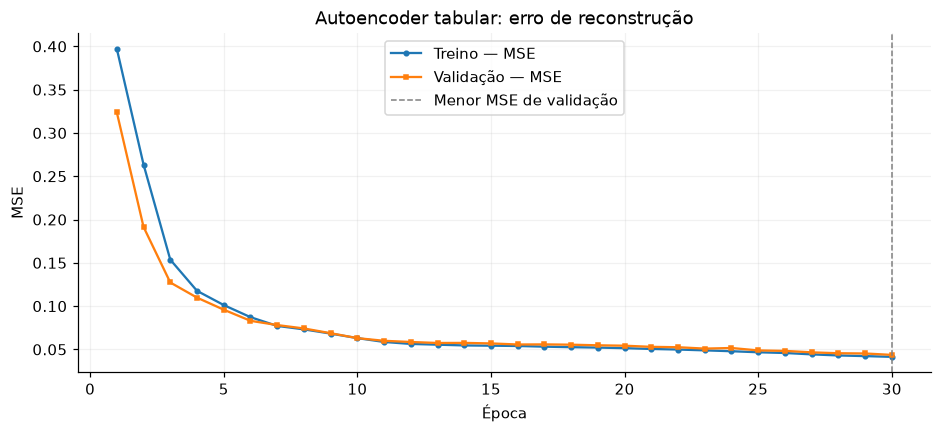

In [5]:
if DL_NETWORK is not None and DL_NETWORK.is_file():
    network_info = read_json(DL_NETWORK)

    history_dl = network_info.get("history", {})
    dl_train_loss = history_dl.get("loss", [])
    dl_val_loss = history_dl.get("val_loss", [])

    if dl_train_loss and dl_val_loss:
        epochs = range(1, len(dl_train_loss) + 1)
        fig, ax = plt.subplots(figsize=(10, 4))

        ax.plot(epochs, dl_train_loss, marker="o", markersize=3, label="Treino — MSE")
        ax.plot(range(1, len(dl_val_loss)+1), dl_val_loss, marker="s", markersize=3,
                label="Validação — MSE")
        
        ax.axvline(float(np.argmin(dl_val_loss) + 1), color="gray", linestyle="--", linewidth=1,
                   label="Menor MSE de validação")
        ax.set(title="Autoencoder tabular: erro de reconstrução", xlabel="Época", ylabel="MSE")
        ax.legend()
        plt.show()
    else:
        warn_missing("O histórico de MSE não está presente em network.json.")
else:
    warn_missing("Gráfico de MSE indisponível: execute a geração das features ou selecione outra rodada.")

Dataset enriquecido: 5,000 linhas × 27 colunas


Partição,train,validation,test
Perfil,,,
0,379,71,91
1,613,120,113
2,730,169,160
3,890,191,196
4,471,94,108
5,422,92,90


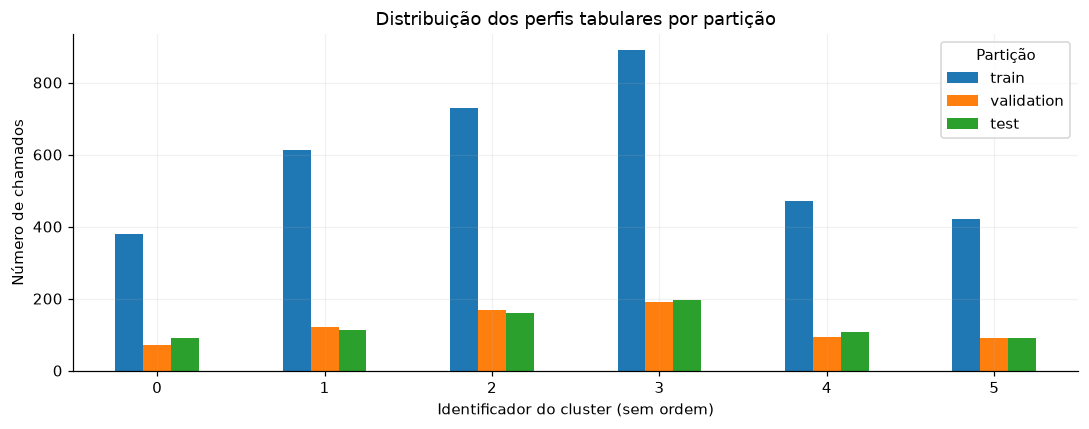

In [6]:
if ENRICHED_PATH is not None and ENRICHED_PATH.is_file():
    enriched = pd.read_parquet(ENRICHED_PATH)

    print(f"Dataset enriquecido: {len(enriched):,} linhas × {len(enriched.columns)} colunas")

    if {"split", "tabular_profile_cluster"}.issubset(enriched.columns):
        distribution = pd.crosstab(
            enriched["tabular_profile_cluster"].astype("string"), enriched["split"]
        ).reindex(columns=["train", "validation", "test"], fill_value=0)
        
        display(distribution.rename_axis(index="Perfil", columns="Partição"))
        ax = distribution.plot.bar(figsize=(10, 4), rot=0)
        ax.set(title="Distribuição dos perfis tabulares por partição",
               xlabel="Identificador do cluster (sem ordem)", ylabel="Número de chamados")
        plt.legend(title="Partição")
        plt.tight_layout()
        plt.show()
    else:
        warn_missing("O Parquet não contém 'split' e 'tabular_profile_cluster'.")
else:
    warn_missing("Distribuição dos clusters indisponível por ausência de enriched.parquet.")

## 3. Composição e funcionamento do multimodal

O classificador final usa early fusion: combina, na mesma matriz de entrada, as colunas estruturadas, os sinais produzidos pelos modelos e as representações TF-IDF dos textos. A previsão de `target_category` acontece somente aqui.

```text
                             Dataset enriquecido
                                    │
           ┌────────────────────────┼────────────────────────┐
           ▼                        ▼                        ▼
   Dados numéricos            Categóricos                  Textos
   (imputação, escala)        (One-Hot)                   (TF-IDF)
     ├─ SLA                    ├─ device_type                ├─ title + description
     ├─ sentimento PLN         ├─ os                         └─ image_description (BLIP)
     ├─ num_words              ├─ network_type
     ├─ image_score            └─ tabular_profile_cluster
     └─ 4 similaridades PLN
           └────────────────────────┬────────────────────────┘
                                    ▼
                         Matriz única de features
                                    ▼
                          MLP (ReLU + Dropout)
                                    ▼
                          Logits → Softmax
                                    ▼
         Software | Rede | Hardware | RH | Acesso | Financeiro
```

O TF-IDF aprende seu vocabulário apenas no treino, enquanto `StandardScaler`, imputação e One-Hot são ajustados sem consultar o teste. A MLP produz seis logits, a maior probabilidade após Softmax define a classe prevista.

A lista efetiva de features e a configuração da rede são lidas automaticamente do YAML na próxima célula.

In [7]:
fusion_cfg = config["multimodal"]
feature_groups = fusion_cfg["features"]
records = []

for name, columns in feature_groups.items():
    if name == "text":
        for block, cols in columns.items():
            for col in cols:
                records.append({"Bloco": f"Texto / {block}", "Feature": col,
                                "Transformação": "TF-IDF independente por bloco"})
    else:
        for col in columns:
            records.append({"Bloco": "Numérico" if name == "numeric" else "Categórico",
                            "Feature": col,
                            "Transformação": "Imputação + StandardScaler" if name == "numeric" else "One-Hot Encoding"})

features_table = pd.DataFrame(records)
display(features_table)
print("Total de colunas de origem no multimodal:", len(features_table))
print("Classes de saída:", " · ".join(fusion_cfg["classes"]))

,Bloco,Feature,Transformação
0,Numérico,sla_hours,Imputação + StandardScaler
1,Numérico,sentiment_score,Imputação + StandardScaler
2,Numérico,num_words,Imputação + StandardScaler
3,Numérico,image_score,Imputação + StandardScaler
4,Numérico,text_failure_similarity,Imputação + StandardScaler
5,Numérico,text_access_request_similarity,Imputação + StandardScaler
6,Numérico,text_guidance_similarity,Imputação + StandardScaler
7,Numérico,text_performance_similarity,Imputação + StandardScaler
8,Categórico,device_type,One-Hot Encoding
9,Categórico,os,One-Hot Encoding


Total de colunas de origem no multimodal: 15
Classes de saída: Software · Rede · Hardware · RH · Acesso · Financeiro


In [8]:
# Parâmetros candidatos presentes na versão ATUAL do YAML.
# Os valores efetivamente selecionados em uma execução aparecem na seção 5.
rows = []

for kind, search in fusion_cfg["search"]["spaces"].items():
    for name, options in search["parameters"].items():
        rows.append({"Modelo": kind.upper(), "Parâmetro": name,
                     "Valores candidatos": repr(options)})
        
display(pd.DataFrame(rows))
display(pd.DataFrame([fusion_cfg["training"]]).T.rename(columns={0: "Valor"}))
print("Métrica para selecionar a melhor tentativa:", fusion_cfg["search"]["metric"])

,Modelo,Parâmetro,Valores candidatos
0,MLP,text_max_features,[1500]
1,MLP,text_min_df,[2]
2,MLP,text_ngram_max,[2]
3,MLP,class_weight,[None]
4,MLP,hidden_dims,"[[64, 128]]"
5,MLP,dropout,[0.3]
6,MLP,learning_rate,[0.001]
7,MLP,weight_decay,[0.0001]
8,MLP,l2_lambda,[0.001]
9,MLP,batch_size,[32]


,Valor
epochs,40.0000
patience,6.0000
min_delta,0.0001
cpu_threads,2.0000


Métrica para selecionar a melhor tentativa: f1_macro


## 4. Por que uma MLP?

A **Multi-Layer Perceptron (MLP)** é adequada para uma primeira fusão de dados heterogêneos porque recebe um vetor numérico único, com TF-IDF, variáveis normalizadas e codificações categóricas e aprende interações não lineares entre esses sinais.

No projeto, cada camada oculta aplica uma transformação linear seguida de ReLU, com Dropout para regularização. O treinamento utiliza AdamW, cross-entropy e early stopping guiado pelo desempenho em validação.

A MLP também não substitui os três geradores, ela aprende a integrar as features já produzidas por visão computacional, PLN e autoencoder tabular para uma melhor classificação. Seu objetivo é prever uma entre as seis categorias de chamados.

## 5. Execução e carregamento da fusão

A célula seguinte reproduz a função `train_fusion()` de `src.models.fusion_pipeline` somente quando `EXECUTAR_TREINAMENTO = True`. Ela usa o Parquet enriquecido de uma execução concluída e cria UMA nova pasta em `reports/fusion/` e `models/fusion/`.

Se `EXECUTAR_TREINAMENTO = False` (padrão), a célula apenas seleciona uma execução já concluída, para uma representação rápida dos dados.

A seleção dos hiperparâmetros ocorre na validação, o teste é usado apenas na avaliação final do vencedor, conforme a metodologia da pipeline.

In [9]:
FUSION_RUN = None

if EXECUTAR_TREINAMENTO:
    if FEATURES_RUN is None or not (FEATURES_RUN / "enriched.parquet").exists():
        raise FileNotFoundError(
            "Não há features completas. Execute primeiro a etapa --features da pipeline "
            "ou configure RODADA_FEATURES com uma rodada válida."
        )

    if ROOT is None:
        raise RuntimeError("A raiz do projeto não foi encontrada.")

    # Import pesado apenas quando um novo treinamento for explicitamente solicitado.
    from src.models.fusion_pipeline import train_fusion
    
    display(Markdown("**Iniciando novo treinamento multimodal a partir dos artefatos existentes...**"))
    FUSION_RUN = train_fusion(config_path=CONFIG_PATH, from_run=FEATURES_RUN, root=ROOT)
else:
    available_fusion = completed_runs(
        fusion_cfg.get("reports_directory", "reports/fusion"), "fusion",
        ("metrics.json", "best_params.yaml", "test_confusion.csv", "test_predictions.parquet"),
    )

    if RODADA_FUSAO:
        FUSION_RUN = rooted(RODADA_FUSAO)

    elif available_fusion:
        # Prioriza execução proveniente da rodada de features selecionada.
        if FEATURES_RUN is not None:
            matches = []

            for candidate in available_fusion:
                source = read_json(candidate / "run.json").get("features_run")
                resolved_source = rooted(source)
                
                if resolved_source is not None and resolved_source.resolve() == FEATURES_RUN.resolve():
                    matches.append(candidate)

            FUSION_RUN = matches[0] if matches else available_fusion[0]
            if not matches:
                print("Aviso: usando uma fusão concluída que pode ter outra origem de features.")
        else:
            FUSION_RUN = available_fusion[0]

if FUSION_RUN is None:
    warn_missing("Nenhuma fusão concluída encontrada. "
                 "Gere as features e ative EXECUTAR_TREINAMENTO na primeira célula.")
else:
    print("Fusão selecionada:", FUSION_RUN.relative_to(ROOT) if ROOT is not None and FUSION_RUN.is_relative_to(ROOT) else FUSION_RUN)

Fusão selecionada: reports\fusion\20261031T063037_445f8d2d


In [11]:
RUN_METADATA = {}
METRICS = None
MODEL_METADATA = {}
ACTUAL_PARAMS = {}
RUN_CONFIG = config

if FUSION_RUN is not None and (FUSION_RUN / "run.json").exists():
    RUN_METADATA = read_json(FUSION_RUN / "run.json")

    if RUN_METADATA.get("status") != "completed":
        warn_missing("A fusão selecionada não foi concluída com sucesso.")

    else:
        metrics_path = FUSION_RUN / "metrics.json"

        if metrics_path.exists():
            METRICS = read_json(metrics_path)

        else:
            warn_missing("A fusão não contém metrics.json.")

        saved_config = FUSION_RUN / "models.yaml"

        if saved_config.exists():
            with saved_config.open(encoding="utf-8") as f:
                RUN_CONFIG = yaml.safe_load(f)

        model_dir = rooted(RUN_METADATA.get("model_directory"))
        if model_dir and (model_dir / "metadata.json").exists():
            MODEL_METADATA = read_json(model_dir / "metadata.json")
            
        ACTUAL_PARAMS = RUN_METADATA.get("best_params") or MODEL_METADATA.get("params", {})

if ACTUAL_PARAMS:
    print("Melhores parâmetros efetivamente registrados para ESSA execução:")
    display(pd.DataFrame([{"Parâmetro": k, "Valor": str(v)} for k, v in ACTUAL_PARAMS.items()]))
    print("Época escolhida:", MODEL_METADATA.get("details", {}).get("best_epoch", "não registrada"))
    print("Dimensão após pré-processamento:", RUN_METADATA.get("input_dimensions", "não registrada"))
    print("Origem do enriched.parquet:", RUN_METADATA.get("features_run") or RUN_METADATA.get("input_file"))
else:
    warn_missing("Os parâmetros da execução não puderam ser carregados.")

Melhores parâmetros efetivamente registrados para ESSA execução:


,Parâmetro,Valor
0,kind,mlp
1,weight_decay,0.0001
2,text_ngram_max,2
3,text_min_df,2
4,text_max_features,1500
5,learning_rate,0.001
6,l2_lambda,0.001
7,hidden_dims,"[64, 128]"
8,dropout,0.3
9,class_weight,None


Época escolhida: 20
Dimensão após pré-processamento: 1320
Origem do enriched.parquet: reports\runs\20261031T045203_ecb5056c


### 5.1. Demonstração de inferência

Quando existirem pesos salvos, a célula carrega o modelo persistido e classifica cinco chamados do conjunto de teste, sem treinar ou reajustar preprocessadores. Esse bloco é exclusivamente demonstrativo: não usa nenhum acerto ou amostra pra escolher hiperparâmetros. Os artefatos restaurados devem vir de uma execução própria e confiável, pois incluem objetos serializados com `joblib`.

In [13]:
if EXECUTAR_DEMONSTRACAO and METRICS is not None and FUSION_RUN is not None:
    source = rooted(RUN_METADATA.get("input_file")) if RUN_METADATA.get("input_file") else None

    if source is None or not source.is_file():
        warn_missing("Parquet de origem não encontrado; a inferência ao vivo será omitida.")

    else:
        try:
            if ROOT is None:
                raise RuntimeError("A raiz do projeto não foi encontrada.")

            from src.models.fusion_pipeline import verify_fusion_run
            from src.models.fusion import EarlyFusionClassifier

            _, artifacts = verify_fusion_run(FUSION_RUN, root=ROOT)
            data_for_prediction = pd.read_parquet(source)
            example = data_for_prediction.loc[data_for_prediction["split"] == "test"].head(5).copy()

            if example.empty:
                raise ValueError("O arquivo não contém linhas do split test.")
            
            loaded_model = EarlyFusionClassifier.restore(artifacts)
            prob = loaded_model.predict_proba(example)
            labels = loaded_model.classes[np.argmax(prob, axis=1)]
            id_col = RUN_CONFIG["global_config"]["split"]["id_column"]
            sample = pd.DataFrame({"ticket_id": example[id_col].astype(str).to_numpy(),
                                   "Classe real": example[RUN_CONFIG["global_config"]["target_col"]].astype(str).to_numpy(),
                                   "Predição": labels,
                                   "Confiança": np.round(prob.max(axis=1), 4)})
            
            display(sample)
            del loaded_model
            
        except (OSError, ValueError, KeyError, ImportError, RuntimeError) as exc:
            warn_missing(f"Não foi possível restaurar a inferência: `{type(exc).__name__}: {exc}`")
else:
    print("Inferência ao vivo desativada ou ainda sem execução concluída.")

,ticket_id,Classe real,Predição,Confiança
0,5,Rede,Rede,0.9947
1,20,Rede,Rede,0.9447
2,24,Acesso,Acesso,0.9827
3,26,Acesso,RH,0.7538
4,28,Hardware,Rede,0.4904


## 6. Curvas, métricas e matriz de confusão

A etapa multimodal salva as métricas de treino, validação e teste em `metrics.json`. Para o modelo MLP, a trajetória por época é persistida em `models/fusion/<id>/metadata.json`, com `train_loss`, `validation_accuracy`, `validation_f1_macro`, `validation_balanced_accuracy` e `validation_log_loss`.

Observação: a loss de treinamento e o *log loss* de validação são relacionadas, mas calculadas sobre partições distintas e não necessariamente com os mesmos pesos por classe, por isso aparecem em curvas identificadas separadamente. O projeto seleciona a melhor época pela métrica configurada em `search.metric`, não necessariamente pelo mínimo de loss.

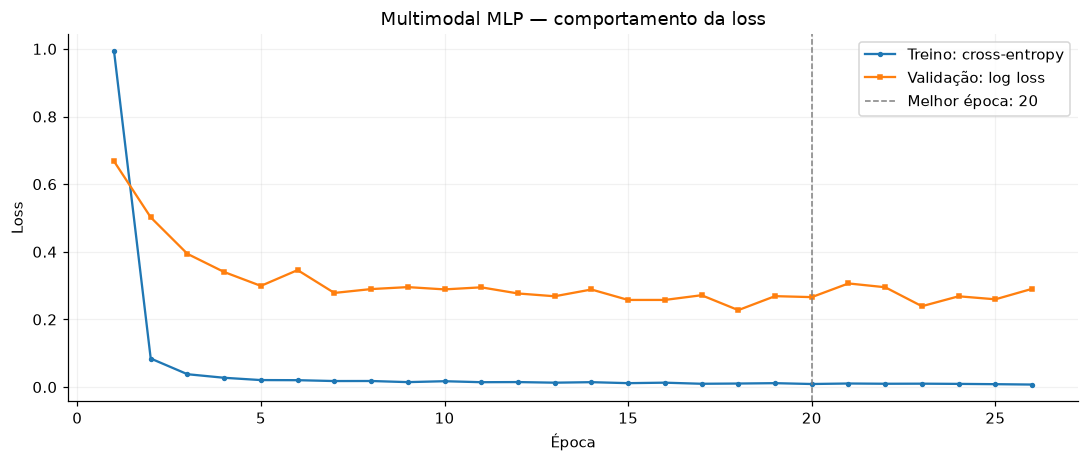

In [14]:
mlp_history = MODEL_METADATA.get("history", [])

if mlp_history:
    hist_df = pd.DataFrame(mlp_history)
    fig, ax = plt.subplots(figsize=(10, 4.3))

    ax.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", markersize=2.5,
            label="Treino: cross-entropy")
    
    if "validation_log_loss" in hist_df:
        ax.plot(hist_df["epoch"], hist_df["validation_log_loss"], marker="s", markersize=2.5,
                label="Validação: log loss")
        
    best_epoch = MODEL_METADATA.get("details", {}).get("best_epoch")
    if best_epoch is not None:
        ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"Melhor época: {best_epoch}")
        
    ax.set(title="Multimodal MLP — comportamento da loss", xlabel="Época", ylabel="Loss")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    warn_missing("Histórico por época indisponível. Use uma execução MLP com metadata.json salvo.")

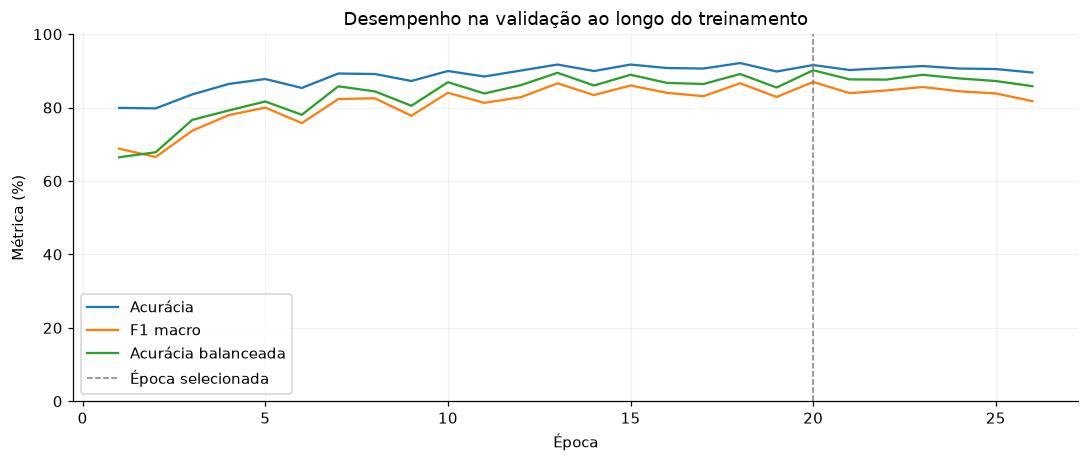

In [15]:
if mlp_history:

    series = [("validation_accuracy", "Acurácia"),
              ("validation_f1_macro", "F1 macro"),
              ("validation_balanced_accuracy", "Acurácia balanceada")]
    
    fig, ax = plt.subplots(figsize=(10, 4.3))
    for name, label in series:
        if name in hist_df:
            ax.plot(hist_df["epoch"], hist_df[name] * 100, label=label)

    best_epoch = MODEL_METADATA.get("details", {}).get("best_epoch")
    if best_epoch is not None:
        ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label="Época selecionada")

    ax.set(title="Desempenho na validação ao longo do treinamento",
           xlabel="Época", ylabel="Métrica (%)", ylim=(0, 100))
    
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    warn_missing("Curvas de validação indisponíveis: falta histórico da MLP.")

,accuracy,balanced_accuracy,f1_macro,log_loss
Treino,99.77%,99.78%,99.75%,0.0067
Validação,91.59%,90.17%,86.97%,0.2660
Teste,76.52%,81.28%,70.92%,0.6457


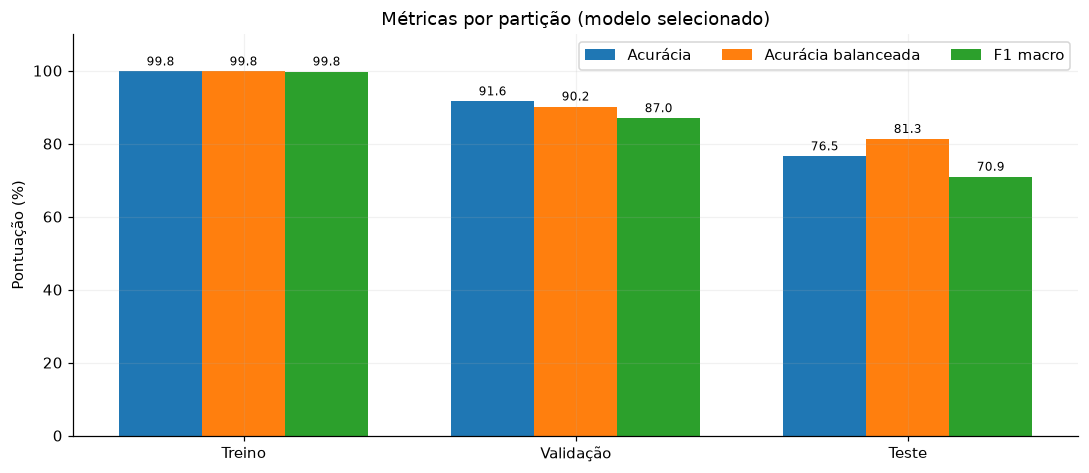

In [16]:
if METRICS is not None:
    keys = ["accuracy", "balanced_accuracy", "f1_macro", "log_loss"]
    ordered = [p for p in ["train", "validation", "test"] if p in METRICS]
    metric_frame = pd.DataFrame.from_dict({p: {k: METRICS[p].get(k, np.nan) for k in keys}
                                          for p in ordered}, orient="index")
    
    display(metric_frame.rename(index={"train": "Treino", "validation": "Validação", "test": "Teste"})
            .style.format({"accuracy": "{:.2%}", "balanced_accuracy": "{:.2%}",
                           "f1_macro": "{:.2%}", "log_loss": "{:.4f}"}))
    
    positions = np.arange(3)
    width = 0.25
    fig, ax = plt.subplots(figsize=(10, 4.4))

    for i, metric in enumerate(["accuracy", "balanced_accuracy", "f1_macro"]):
        heights = [100 * METRICS[p][metric] for p in ordered]
        bars = ax.bar(np.arange(len(ordered)) + (i-1) * width, heights, width,
                      label={"accuracy": "Acurácia", "balanced_accuracy": "Acurácia balanceada",
                             "f1_macro": "F1 macro"}[metric])
        
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
        
    ax.set_xticks(np.arange(len(ordered)), ["Treino" if p == "train" else "Validação" if p == "validation" else "Teste" for p in ordered])
    ax.set(title="Métricas por partição (modelo selecionado)", ylabel="Pontuação (%)", ylim=(0, 110))
    ax.legend(ncol=3)
    plt.tight_layout()
    plt.show()
else:
    warn_missing("Tabela e gráfico de métricas indisponíveis: sem metrics.json.")

### 6.1. Matriz de confusão — Teste

Linhas representam as classes reais, colunas as classes previstas. A diagonal representa os acertos, o segundo gráfico normaliza cada linha para facilitar comparações entre categorias que têm quantidades de chamados diferentes.

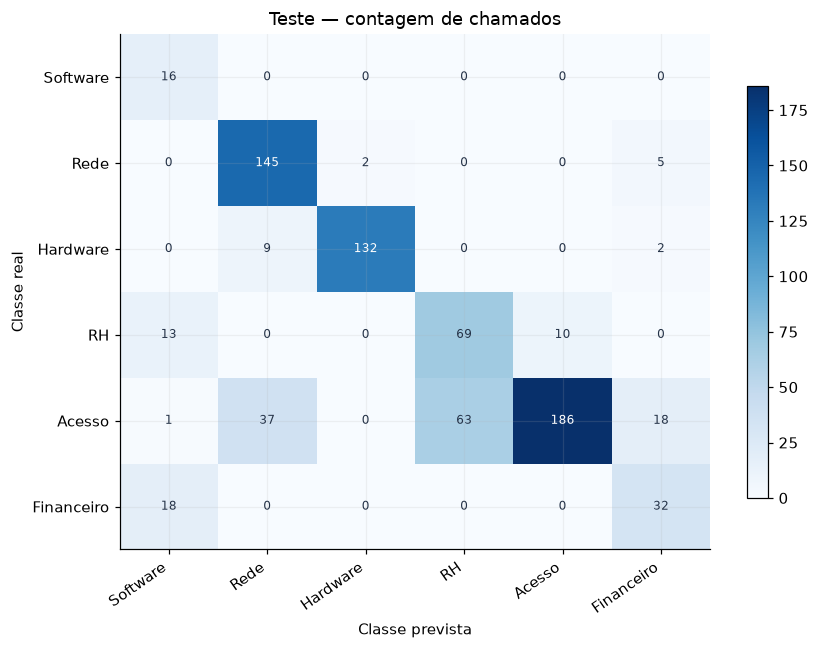

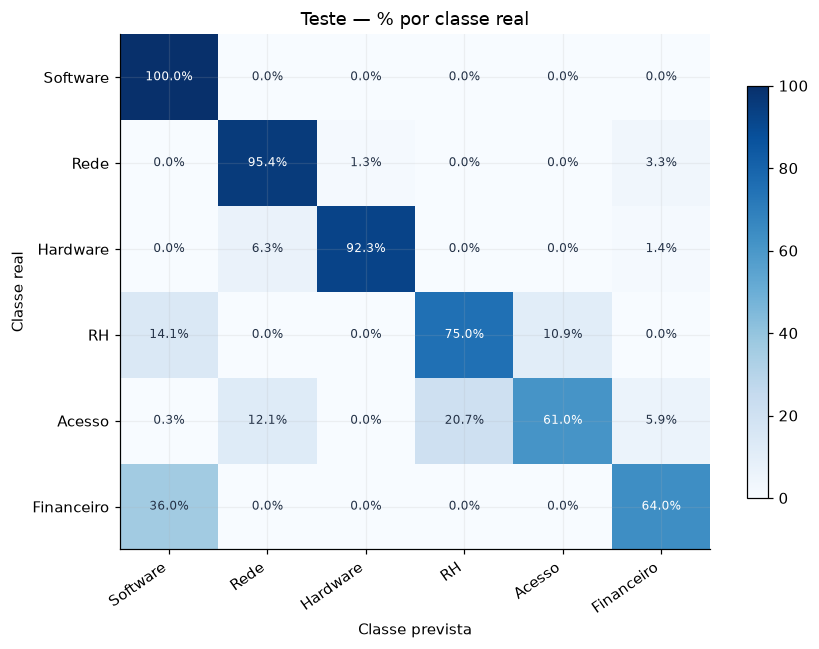

In [17]:
confusion_file = FUSION_RUN / "test_confusion.csv" if FUSION_RUN else None

if confusion_file is not None and confusion_file.is_file():
    matrix = pd.read_csv(confusion_file, index_col=0)
    matrix = matrix.apply(pd.to_numeric, errors="raise")
    matrix_percent = matrix.div(matrix.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100

    for data, title, suffix in [(matrix, "Teste — contagem de chamados", ""),
                                (matrix_percent, "Teste — % por classe real", "%")]:
        
        fig, ax = plt.subplots(figsize=(8, 6))
        image = ax.imshow(data.values, cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(data.columns)), data.columns, rotation=35, ha="right")
        ax.set_yticks(range(len(data.index)), data.index)
        ax.set(title=title, xlabel="Classe prevista", ylabel="Classe real")

        for (i, j), value in np.ndenumerate(data.values):
            ax.text(j, i, f"{value:.1f}%" if suffix else str(int(value)),
                    ha="center", va="center", fontsize=8,
                    color="white" if value > np.nanmax(data.values) * .55 else "#243247")
            
        fig.colorbar(image, ax=ax, shrink=.8)
        plt.tight_layout()
        plt.show()
else:
    warn_missing("Matriz de confusão de teste não encontrada: test_confusion.csv.")

### 6.2. Desempenho por categoria

O F1 por classe complementa a acurácia agregada. Também é importante olhar o suporte (quantidade de exemplos) para identificar possíveis diferenças de representatividade, especialmente entre validação e teste.

,Precisão,Recall,F1,Quantidade
Software,33.33%,100.00%,50.00%,16
Rede,75.92%,95.39%,84.55%,152
Hardware,98.51%,92.31%,95.31%,143
RH,52.27%,75.00%,61.61%,92
Acesso,94.90%,60.98%,74.25%,305
Financeiro,56.14%,64.00%,59.81%,50


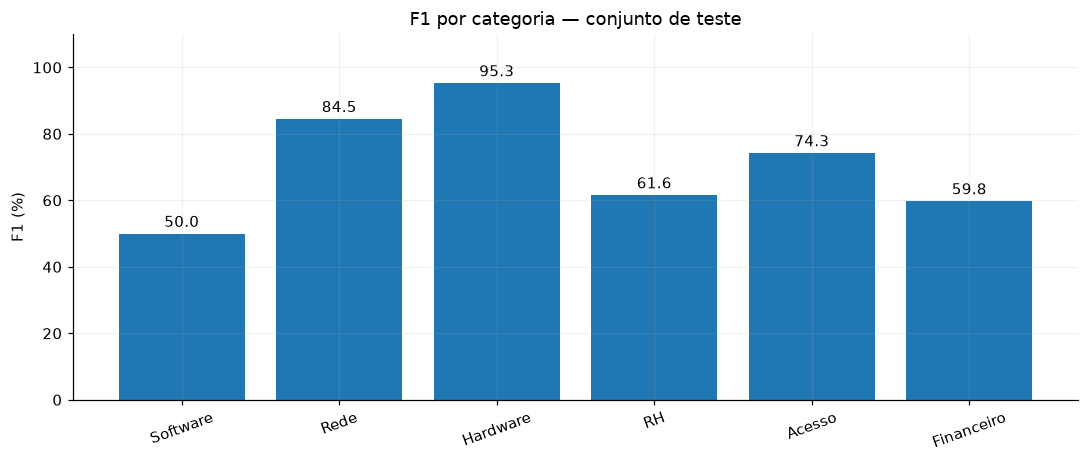

In [18]:
if METRICS is not None and "test" in METRICS:
    reports = METRICS["test"].get("classification_report", {})
    classes = RUN_CONFIG["multimodal"]["classes"]
    class_table = pd.DataFrame({name: reports[name] for name in classes if name in reports}).T

    if not class_table.empty:
        display(class_table.rename(columns={"precision": "Precisão", "recall": "Recall",
                                            "f1-score": "F1", "support": "Quantidade"})
                .style.format({"Precisão": "{:.2%}", "Recall": "{:.2%}", "F1": "{:.2%}",
                               "Quantidade": "{:.0f}"}))
        
        fig, ax = plt.subplots(figsize=(10, 4.3))
        bars = ax.bar(class_table.index, class_table["f1-score"] * 100)
        ax.bar_label(bars, fmt="%.1f", padding=2)
        ax.set(title="F1 por categoria — conjunto de teste", ylabel="F1 (%)", ylim=(0, 110))
        
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()
else:
    warn_missing("Relatório por categoria indisponível.")

## 7. Resultados finais e interpretação

A seguir, o resumo final é preenchido dinamicamente pelas métricas da rodada selecionada. A finalidade é apresentar o resultado obtido, sem fixar no notebook os percentuais de uma execução antiga.

Na leitura do resultado, considere: (1) a acurácia, como fração geral de acertos, (2) o F1 macro, que pondera cada classe igualmente, (3) a acurácia balanceada, média do recall entre classes e (4) o log loss, que leva em conta as probabilidades previstas.

In [19]:
if METRICS is not None and "test" in METRICS and FUSION_RUN is not None:
    test = METRICS["test"]
    validation = METRICS.get("validation", {})
    train = METRICS.get("train", {})
    diff = (validation.get("accuracy", float("nan")) - test["accuracy"]) * 100
    gap = (train.get("accuracy", float("nan")) - test["accuracy"]) * 100
    parts = RUN_METADATA.get("partition_rows", {})
    
    summary = f"""
### Resultado da execução `{FUSION_RUN.name}`

| Indicador | Resultado no teste |
|:--|--:|
| **Acurácia** | **{test['accuracy']:.2%}** |
| **F1 macro** | **{test['f1_macro']:.2%}** |
| Acurácia balanceada | {test['balanced_accuracy']:.2%} |
| Log loss | {test['log_loss']:.4f} |
| Exemplos no teste | {parts.get('test', 'não informado')} |

**Comparação entre partições:** diferença de acurácia validação − teste = **{diff:+.2f} p.p.**; treino − teste = **{gap:+.2f} p.p.**

**Proveniência:** experimento de fusão `{FUSION_RUN.name}`; seleção por `{RUN_METADATA.get('selection_metric', 'não informado')}`; configuração e artefatos preservados na própria execução.
"""
    display(Markdown(summary))
else:
    warn_missing("Resultados finais ainda indisponíveis. Selecione uma execução concluída ou treine a fusão.")


### Resultado da execução `20261031T063037_445f8d2d`

| Indicador | Resultado no teste |
|:--|--:|
| **Acurácia** | **76.52%** |
| **F1 macro** | **70.92%** |
| Acurácia balanceada | 81.28% |
| Log loss | 0.6457 |
| Exemplos no teste | 758 |

**Comparação entre partições:** diferença de acurácia validação − teste = **+15.07 p.p.**; treino − teste = **+23.25 p.p.**

**Proveniência:** experimento de fusão `20261031T063037_445f8d2d`; seleção por `f1_macro`; configuração e artefatos preservados na própria execução.


### Conclusões e limitações

- O deep learning tabular cria perfis latentes com reconstrução e clusterização, dependendo do `sentiment_score` estimado antes pelo PLN. Não recebe os rótulos de categoria durante seu treinamento e não classifica nada com o KNN.
- O multimodal utiliza as features dos três geradores e os dados originais, a MLP aprende interações não lineares para classificar o chamado em seis categorias.
- MSE do autoencoder não é acurácia, e a qualidade do cluster depende de sua contribuição observada no modelo final.
- A natureza sintética dos chamados e a variedade limitada de imagens impedem extrapolar diretamente o desempenho para uma central de suporte real ou aplicação prática dos modelos.

**Arquivos principais relacionados:** `src/models/profiles.py`, `src/models/language.py`, `src/models/vision.py`, `src/models/fusion.py`, `src/models/fusion_pipeline.py`, `src/config/models.yaml` e `reports/fusion/<execução>/`.

**Repositório:** [ProjetoIntegrador-II](https://github.com/AndreyFernandes-NP/ProjetoIntegrador-II)